<a id="toc"></a>
# Cookie Cats — A/B Test Analysis: Gate Level 30 vs. Gate Level 40

**Dataset:** [Mobile Games A/B Testing — Cookie Cats](https://www.kaggle.com/datasets/mursideyarkin/mobile-games-ab-testing-cookie-cats) (Kaggle)

| Column | Description |
|---|---|
| `userid` | Unique player ID |
| `version` | Group the player was in: `gate_30` (control) or `gate_40` (treatment) |
| `sum_gamerounds` | Number of game rounds played in the first 14 days after install |
| `retention_1` | Did the player come back 1 day after installing? |
| `retention_7` | Did the player come back 7 days after installing? |

**Business question:** Does delaying the first gate from level 30 to level 40 help or hurt player retention?
Tactile's hypothesis was that more gameplay before the first paywall would increase engagement —
this notebook checks whether the data actually supports that.



## Table of Contents
1. [Setup & Imports](#setup)
2. [Load Data](#load)
3. [Data Quality Checks & Validation](#quality)
4. [Exploratory Data Analysis](#eda)
    - 4.1 [Distribution of `sum_gamerounds`](#dist)
    - 4.2 [Outlier Handling](#outliers)
    - 4.3 [Log Transformation](#log)
5. [Retention Overview](#retention)
6. [Sample Ratio Mismatch (SRM) Check](#srm)
7. [Hypothesis Formulation](#hypothesis)
8. [Statistical Testing — Retention](#retention-test)
9. [Statistical Testing — Engagement (`sum_gamerounds`)](#engagement-test)
10. [Confidence Intervals & Effect Size](#ci-effect)
11. [Statistical Power Analysis](#power)
12. [Multiple Comparisons Correction](#multi-comp)
13. [Deeper Analysis — Bootstrap Simulation](#bootstrap)
14. [Deeper Analysis — Segmentation](#segmentation)
15. [Bayesian A/B Test](#bayesian)
16. [Interpretation & Business Framing](#interpretation)
17. [Final Conclusion & Recommendation](#conclusion)

<a id="setup"></a>
## 1. Setup & Imports

[⬆ back to top](#toc)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import chisquare, shapiro, probplot, mannwhitneyu
from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep,
    proportion_effectsize,
)
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.multitest import multipletests

plt.rcParams['figure.figsize'] = (6, 5)
plt.rcParams['font.size'] = 12
# plt.style.use('seaborn-v0_8-whitegrid')
# plt.style.use('ggplot')
# plt.style.use('seaborn-v0_8-darkgrid')
# plt.style.use('fivethirtyeight')
plt.style.use('seaborn-v0_8-white')
# plt.style.use('dark_background')
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
ALPHA = 0.05          # study-wide significance level
RANDOM_SEED = 42       # fixed seed for every stochastic step (sampling, bootstrap, Bayesian draws)
colors = ['steelblue', 'orange', 'seagreen', 'crimson', 'purple', 'mediumpurple', 'gold', 'teal', 'slategray', 'sienna','indianred']

In [2]:
# --------------------------------------------------------------------
# Reusable helper functions
# --------------------------------------------------------------------
# Industry note: repeating the same 8-line "z-test + CI + effect size" block
# in every section (as the first draft of this notebook did) is a common
# source of copy-paste bugs — e.g. the CI method or group labels silently
# drifting between sections. Centralizing the logic in one tested function
# means every test in this notebook is guaranteed to use the same
# statistical method, and the method only needs to be changed in one place.

def run_two_proportion_test(df, metric, group_col='version',
                             control_label='gate_30', treatment_label='gate_40',
                             ci_method='newcomb'):
    """Two-proportion z-test + confidence interval + effect size for a binary metric.

    Parameters
    ----------
    ci_method : str
        Method passed to statsmodels' confint_proportions_2indep. We default to
        'newcomb' (a Wilson-score-based interval) rather than 'wald', because
        the Wald interval is known to have poor coverage for proportions,
        especially away from 50% — Newcomb's method is the more defensible
        industry-standard choice here.

    Returns
    -------
    dict with rates, difference, 95% CI, z-statistic, p-value, Cohen's h, and
    the two group sizes.
    """
    control = df[df[group_col] == control_label][metric]
    treatment = df[df[group_col] == treatment_label][metric]

    n_control, n_treatment = len(control), len(treatment)
    success_control, success_treatment = control.sum(), treatment.sum()

    z_stat, p_value = proportions_ztest(
        [success_treatment, success_control],
        [n_treatment, n_control]
    )

    ci_low, ci_high = confint_proportions_2indep(
        success_treatment, n_treatment,
        success_control, n_control,
        method=ci_method
    )

    control_rate = control.mean()
    treatment_rate = treatment.mean()
    cohens_h = proportion_effectsize(treatment_rate, control_rate)

    return {
        'metric': metric,
        'control_rate': control_rate,
        'treatment_rate': treatment_rate,
        'diff': treatment_rate - control_rate,
        'ci_low': ci_low,
        'ci_high': ci_high,
        'z_stat': z_stat,
        'p_value': p_value,
        'cohens_h': cohens_h,
        'n_control': n_control,
        'n_treatment': n_treatment,
    }


def print_test_result(result, alpha=ALPHA):
    """Pretty-print the dict returned by run_two_proportion_test."""
    r = result
    print(f"Metric:              {r['metric']}")
    print(f"Control (gate_30):   {r['control_rate']:.2%}  (n={r['n_control']:,})")
    print(f"Treatment (gate_40): {r['treatment_rate']:.2%}  (n={r['n_treatment']:,})")
    print(f"Difference:          {r['diff']:.2%}")
    print(f"95% CI (Newcomb):    ({r['ci_low']:.2%}, {r['ci_high']:.2%})")
    print(f"Z-statistic:         {r['z_stat']:.4f}")
    print(f"P-value:             {r['p_value']:.4f}")
    print(f"Cohen's h:           {r['cohens_h']:.4f}")
    verdict = "Reject H0" if r['p_value'] < alpha else "Fail to reject H0"
    print(f"Verdict @ alpha={alpha}: {verdict}")

<a id="load"></a>
## 2. Load Data

[⬆ back to top](#toc)

In [3]:
df = pd.read_csv("../data/cookie_cats.csv")
df.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


<a id="quality"></a>
## 3. Data Quality Checks & Validation

[⬆ back to top](#toc)

In [4]:
# Quick structural check: data types of each column.
df.dtypes

userid            int64
version             str
sum_gamerounds    int64
retention_1        bool
retention_7        bool
dtype: object

In [5]:
# Check for missing values in every column.
df.isnull().sum()

userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64

In [6]:
# check for duplicate data
df.duplicated().sum()

np.int64(0)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   userid          90189 non-null  int64
 1   version         90189 non-null  str  
 2   sum_gamerounds  90189 non-null  int64
 3   retention_1     90189 non-null  bool 
 4   retention_7     90189 non-null  bool 
dtypes: bool(2), int64(2), str(1)
memory usage: 2.8 MB


In [8]:
# Schema validation (flag any error before the test begins)
assert df['userid'].is_unique, "Duplicate userid found — a player should appear exactly once"
assert set(df['version'].unique()) == {'gate_30', 'gate_40'}, "Unexpected value in 'version'"
assert df['sum_gamerounds'].ge(0).all(), "sum_gamerounds should never be negative"
assert df['retention_1'].isin([True, False]).all(), "retention_1 should be strictly boolean"
assert df['retention_7'].isin([True, False]).all(), "retention_7 should be strictly boolean"
# Retention is not increasing in the wrong direction: nothing enforces retention_7 <= retention_1
# logically (a player could churn day 1 and return day 7), so we don't assert an ordering here —
# just confirming that both columns are well-formed.
print("All schema checks passed.")

All schema checks passed.


In [9]:
# Sanity check that userid is actually numeric (it should be, since it's an ID).
pd.api.types.is_numeric_dtype(df['userid'])

True

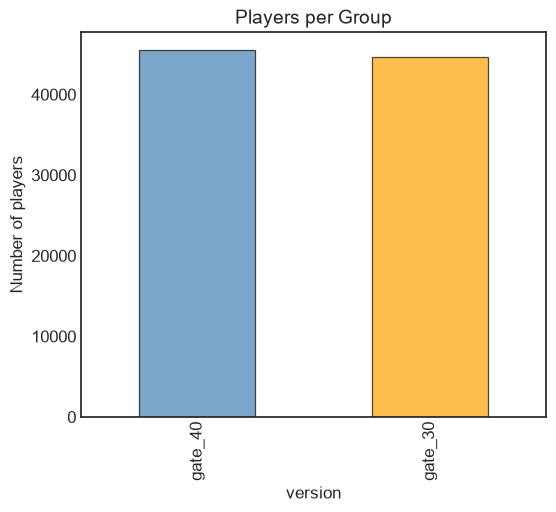

In [10]:
# Every player should be in exactly one experiment group.
df['version'].value_counts().plot(kind='bar', title='Players per Group',color=colors, edgecolor='black', alpha=0.7,linewidth=0.9)
plt.ylabel('Number of players')
plt.show()

<a id="eda"></a>
## 4. Exploratory Data Analysis

[⬆ back to top](#toc)

<a id="dist"></a>
### 4.1 Distribution of `sum_gamerounds`

In [11]:
# Summary statistics for the main engagement metric.
# Note the huge gap between the 75th percentile and the max gives a strong hint of a heavily right-skewed distribution with extreme outliers.
df['sum_gamerounds'].describe()

count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64

Counts: [90188     0     0     0     1]
Bin edges: [    0.   9970.8 19941.6 29912.4 39883.2 49854. ]


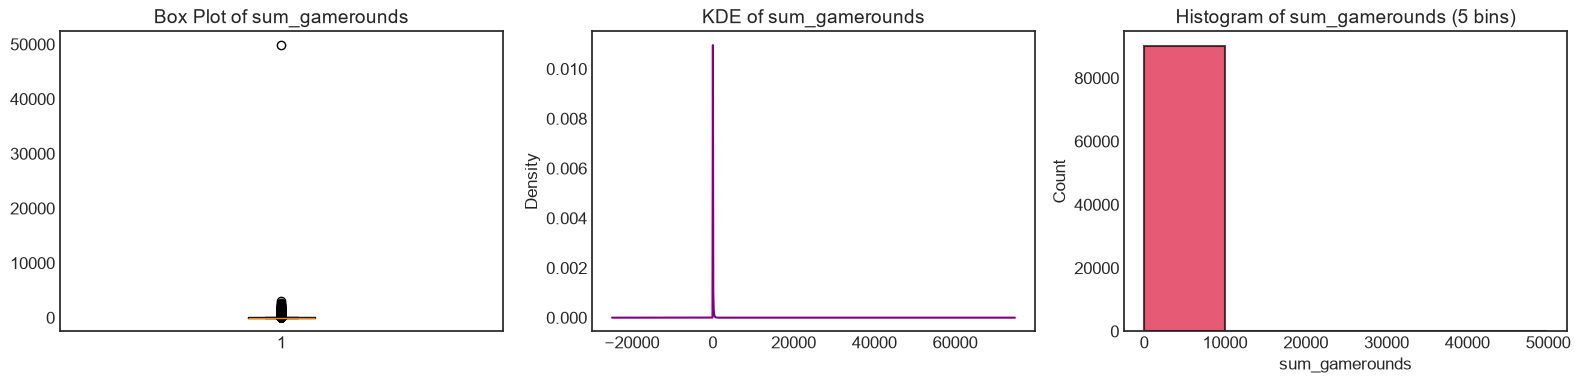

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

# Box plot
ax[0].boxplot(df['sum_gamerounds'])
ax[0].set_title('Box Plot of sum_gamerounds')


# KDE plot
df['sum_gamerounds'].plot(
    kind='kde',
    ax=ax[1],
    color='purple'
)
ax[1].set_title('KDE of sum_gamerounds')

counts, bin_edges = np.histogram(df['sum_gamerounds'], bins=5)
print("Counts:", counts)
print("Bin edges:", bin_edges)

#Histogram
width = bin_edges[1] - bin_edges[0]
ax[2].bar(bin_edges[:-1], counts, width=width, align='edge', color='crimson',alpha=0.7, linewidth=1.5, edgecolor="black")
ax[2].set_xlabel('sum_gamerounds')
ax[2].set_ylabel('Count')
ax[2].set_title('Histogram of sum_gamerounds (5 bins)')

plt.tight_layout()
plt.show()

<a id="outliers"></a>
### 4.2 Outlier Handling

In [13]:
# One player has an implausibly high sum_gamerounds value (a likely bot or data-entry error) that dwarfs everyone else and distorts every plot/statistic.
max_rounds = df['sum_gamerounds'].max()
outlier_rows = df[df['sum_gamerounds'] == max_rounds]

# This is >100x the 99.9th percentile of the rest of the distribution:
# 1071.0649999999732
# Treated as a data-quality issue (bot/instrumentation error), not a genuine engaged player, and removed from the analysis dataset below.

df = df.drop(outlier_rows.index)

In [14]:
counts, bin_edges = np.histogram(df['sum_gamerounds'], bins=10)
print("Counts:", counts)
print("Bin edges:", bin_edges)
# We won't remove any more points — the remaining tail is real signal (a small number of very engaged players), not noise. To visualize a heavily skewed count
# variable like this, a log transform (or log-scaled axis) is the standard approach, since it turns the long tail into something closer to an interpretable shape.

Counts: [87446  2212   376    88    39    16     4     4     2     1]
Bin edges: [   0.   296.1  592.2  888.3 1184.4 1480.5 1776.6 2072.7 2368.8 2664.9
 2961. ]


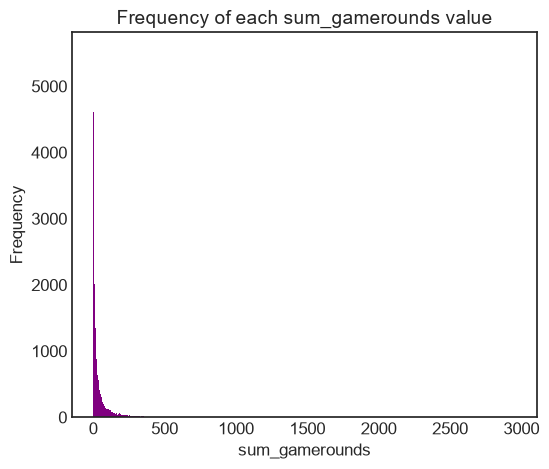

In [15]:
# Frequency of every individual value of sum_gamerounds (no binning) — a
# smoother-looking curve than a fixed-bin histogram since there's no bin-width choice involved.
counts = df['sum_gamerounds'].value_counts().sort_index()

plt.bar(counts.index, counts.values, width=1,color='purple')
plt.xlabel('sum_gamerounds')
plt.ylabel('Frequency')
plt.title('Frequency of each sum_gamerounds value')
plt.show()


<a id="log"></a>
### 4.3 Log Transformation

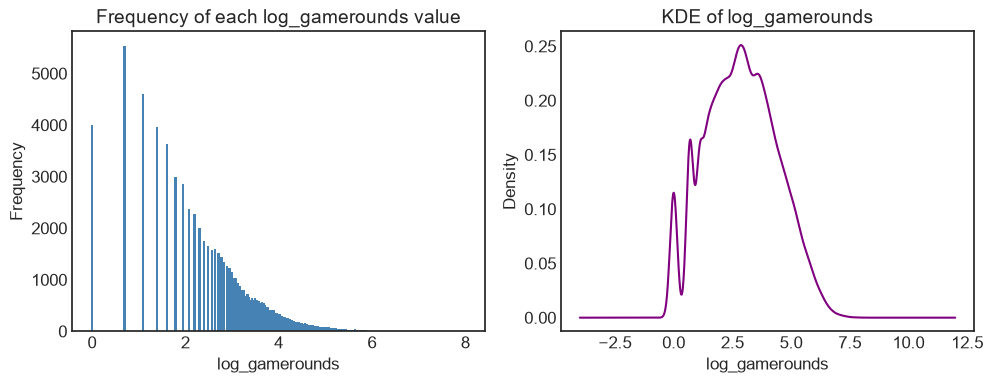

In [16]:
# log1p (log(1+x)) handles the x=0 case cleanly and compresses the long right tail, making the distribution far easier to visualize.
df['log_gamerounds'] = np.log1p(df['sum_gamerounds'])

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# Bar plot
counts = df['log_gamerounds'].value_counts().sort_index()

ax[0].bar(
    counts.index,
    counts.values,
    width=0.05,
    color='steelblue'
)

ax[0].set_xlabel('log_gamerounds')
ax[0].set_ylabel('Frequency')
ax[0].set_title('Frequency of each log_gamerounds value')


# KDE plot
df['log_gamerounds'].plot(
    kind='kde',
    ax=ax[1],
    color='purple'
)

ax[1].set_xlabel('log_gamerounds')
ax[1].set_ylabel('Density')
ax[1].set_title('KDE of log_gamerounds')

plt.tight_layout()
plt.show()

In [17]:
df['log_gamerounds'].describe()

count    90188.000000
mean         2.879658
std          1.503568
min          0.000000
25%          1.791759
50%          2.833213
75%          3.951244
max          7.993620
Name: log_gamerounds, dtype: float64

<a id="retention"></a>
## 5. Retention Overview

[⬆ back to top](#toc)

In [18]:
print("retention_1 value counts:")
print(df['retention_1'].value_counts())
print()
print("retention_7 value counts:")
print(df['retention_7'].value_counts())

retention_1 value counts:
retention_1
False    50035
True     40153
Name: count, dtype: int64

retention_7 value counts:
retention_7
False    73408
True     16780
Name: count, dtype: int64


In [19]:
df1=df['retention_1'].value_counts()
df2=df['retention_7'].value_counts()
combined = pd.concat([df1, df2], axis=1)

combined.columns = ['retention_1', 'retention_7']

print(combined)

       retention_1  retention_7
False        50035        73408
True         40153        16780


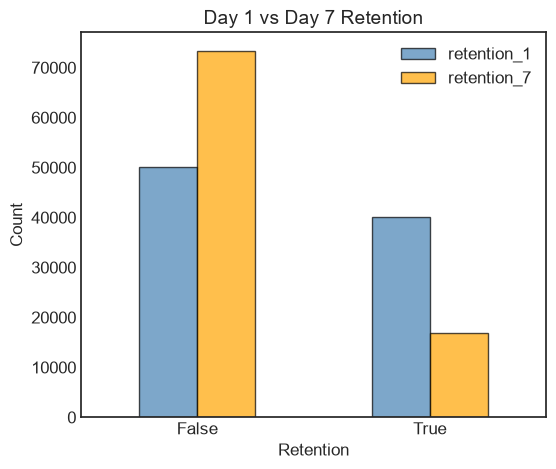

In [20]:
combined.plot(kind='bar',color=colors,alpha=0.7, linewidth=1.0, edgecolor="black")

plt.xlabel('Retention')
plt.ylabel('Count')
plt.title('Day 1 vs Day 7 Retention')
plt.xticks(rotation=0)
plt.legend()
plt.show()


<a id="srm"></a>
## 6. Sample Ratio Mismatch (SRM) Check

[⬆ back to top](#toc)

Before trusting any A/B test result, we should confirm the randomization
actually produced a roughly 50/50 split between groups. A large imbalance
(a "sample ratio mismatch") can be a sign of a broken experiment — e.g. a bug
in the assignment logic, or bots being disproportionately routed to one arm.

**Limitation:** this dataset has no install-date/timestamp column, so we can
only check the *overall* split, not whether the ratio held steady day-by-day
over the course of the experiment (a stronger SRM check would also plot the
daily allocation ratio to catch issues that only appear partway through). See
[Limitations](#limitations) for more on this.

In [21]:
gate_count = df['version'].value_counts().reset_index()
gate_count.columns = ['version', 'count']

gate_count['expected_count'] = len(df) / 2
gate_count['actual_minus_expected'] = (gate_count['expected_count'] - gate_count['count']).abs()
gate_count

,version,count,expected_count,actual_minus_expected
0,gate_40,45489,45094.0,395.0
1,gate_30,44699,45094.0,395.0


In [22]:
# A chi-square goodness-of-fit test formalizes the SRM check: under the null
# hypothesis of a true 50/50 split, do the observed group counts look
# plausible? By default chisquare() compares against a uniform expected
# distribution, which is exactly what we want here.

# The null hypothesis is:
# H₀: The observed data follows the expected distribution.
# H₁: The observed data does not follow the expected distribution.
observed = df['version'].value_counts()
chi2_stat, srm_p_value = chisquare(observed)

print("Chi-square statistic:", chi2_stat) #It measures how far your observed counts are from the expected counts.
# small chi2 → observed ≈ expected
# large chi2 → observed is far from expected
print("p-value:", srm_p_value)

# Industry convention: SRM checks commonly use a stricter threshold (e.g. 0.01
# or even 0.001) than the usual 0.05, because a false "SRM detected" alarm is
# cheap to investigate, while missing a real SRM can invalidate the whole
# experiment.
if srm_p_value < 0.01:
    print("Possible SRM: group sizes deviate significantly from 50/50. Investigate before trusting results.")
else:
    print("No evidence of sample ratio mismatch — group sizes are consistent with a 50/50 split.")


Chi-square statistic: 6.919989355568369
p-value: 0.008523748341090839
Possible SRM: group sizes deviate significantly from 50/50. Investigate before trusting results.


In [23]:
dup_userids = df.duplicated(subset=['userid']).sum()
print("Duplicate userids found:", dup_userids)

Duplicate userids found: 0


<a id="hypothesis"></a>
## 7. Hypothesis Formulation

[⬆ back to top](#toc)

**Primary hypotheses (retention):**
- **H0:** retention is equal between `gate_30` and `gate_40`.
- **H1:** retention is *not* equal between `gate_30` and `gate_40`.
- **Significance level:** α = 0.05, tested for both `retention_1` and `retention_7`.

**Secondary hypothesis (engagement):**
- **H0:** the distribution of `sum_gamerounds` is equal between groups.
- **H1:** the distributions differ.

Because we are running multiple hypothesis tests against the same experiment
(1-day retention, 7-day retention, engagement, plus two engagement-segment
cuts later on), we apply a multiple-comparisons correction in
[Section 12](#multi-comp) before drawing final conclusions — testing several
hypotheses at an uncorrected α = 0.05 each inflates the chance of a false
positive across the family of tests.

<a id="retention-test"></a>
## 8. Statistical Testing — Retention

[⬆ back to top](#toc)

In [24]:
# Two-proportion z-test comparing Day-1 retention rates between the two groups,
# using the reusable helper defined in Section 1.
result_r1 = run_two_proportion_test(df, metric='retention_1')
print_test_result(result_r1)


Metric:              retention_1
Control (gate_30):   44.82%  (n=44,699)
Treatment (gate_40): 44.23%  (n=45,489)
Difference:          -0.59%
95% CI (Newcomb):    (-1.24%, 0.06%)
Z-statistic:         -1.7871
P-value:             0.0739
Cohen's h:           -0.0119
Verdict @ alpha=0.05: Fail to reject H0


In [25]:
# Repeat for 7-day retention.
result_r7 = run_two_proportion_test(df, metric='retention_7')
print_test_result(result_r7)


Metric:              retention_7
Control (gate_30):   19.02%  (n=44,699)
Treatment (gate_40): 18.20%  (n=45,489)
Difference:          -0.82%
95% CI (Newcomb):    (-1.33%, -0.31%)
Z-statistic:         -3.1574
P-value:             0.0016
Cohen's h:           -0.0210
Verdict @ alpha=0.05: Reject H0


Both point the same direction (gate_30 retains slightly better), but only
`retention_7` is significant at the uncorrected α = 0.05 — we revisit this
after applying the multiple-comparisons correction in
[Section 12](#multi-comp).

<a id="engagement-test"></a>
## 9. Statistical Testing — Engagement (`sum_gamerounds`)

[⬆ back to top](#toc)

#### Check normality with Shapiro-Wilk

In [26]:
control_rounds = df[df['version'] == 'gate_30']['sum_gamerounds']
treatment_rounds = df[df['version'] == 'gate_40']['sum_gamerounds']

# FIX: scipy's Shapiro-Wilk test is only validated for N <= 5000 and prints a
# UserWarning above that size (our groups have ~45,000 rows each). We take a
# fixed-size random sample from each group so the test statistic is both
# valid and reproducible, rather than silently running it on the full data.
sample_size = min(5000, len(control_rounds), len(treatment_rounds))
stat_control, p_control = shapiro(control_rounds.sample(sample_size, random_state=RANDOM_SEED))
stat_treatment, p_treatment_norm = shapiro(treatment_rounds.sample(sample_size, random_state=RANDOM_SEED))

print("Control p-value:", p_control)
print("Treatment p-value:", p_treatment_norm)

if p_control < 0.05 or p_treatment_norm < 0.05:
    print("At least one group is non-normal -> use Mann-Whitney U test")
else:
    print("Both groups appear normal -> a parametric test may be considered")

# Note: with very large samples, Shapiro-Wilk will often reject normality even
# for minor deviations. A Q-Q plot (below) is a useful complementary check.


Control p-value: 2.214449207778428e-80
Treatment p-value: 4.4875966829515605e-79
At least one group is non-normal -> use Mann-Whitney U test


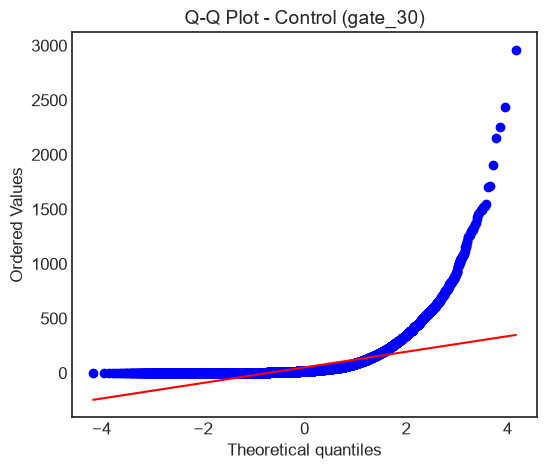

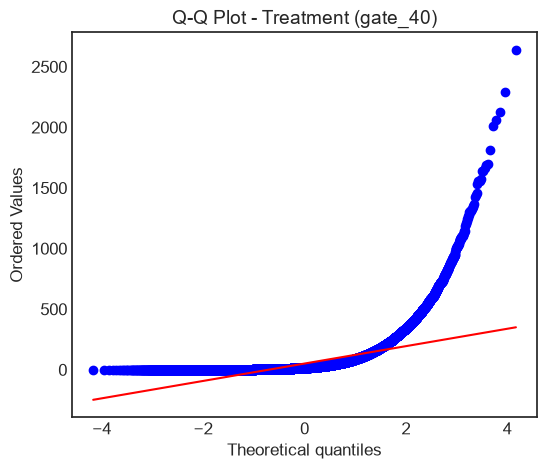

In [27]:
plt.figure(figsize=(6, 5))
probplot(control_rounds, dist="norm", plot=plt)
plt.title("Q-Q Plot - Control (gate_30)")
plt.show()

plt.figure(figsize=(6, 5))
probplot(treatment_rounds, dist="norm", plot=plt)
plt.title("Q-Q Plot - Treatment (gate_40)")
plt.show()

# Both plots curve heavily away from the reference line, confirming the data
# is not normally distributed -- a non-parametric test is the right choice.


In [28]:
# sum_gamerounds is heavily right-skewed, so the mean is pulled upward by a
# few very engaged players -- the median is a more robust summary here.
print("Control median:", control_rounds.median())
print("Treatment median:", treatment_rounds.median())
print("Control mean:", control_rounds.mean())
print("Treatment mean:", treatment_rounds.mean())


Control median: 17.0
Treatment median: 16.0
Control mean: 51.342110561757536
Treatment mean: 51.29877552814966


In [29]:
# Mann-Whitney U test: a non-parametric alternative that compares
# distributions without assuming normality.
u_stat, mw_p_value = mannwhitneyu(control_rounds, treatment_rounds, alternative='two-sided')

print("Mann-Whitney U statistic:", u_stat)
print("p-value:", mw_p_value)

if mw_p_value < ALPHA:
    print("Reject H0: significant difference in engagement between groups (uncorrected alpha).")
else:
    print("Fail to reject H0: no significant difference in engagement between groups.")


Mann-Whitney U statistic: 1024285761.5
p-value: 0.05089155279145376
Fail to reject H0: no significant difference in engagement between groups.


<a id="ci-effect"></a>
## 10. Confidence Intervals & Effect Size

[⬆ back to top](#toc)

In [30]:
# The 1-day retention result already includes a 95% CI (Newcomb method) and
# Cohen's h from the helper function in Section 8 -- reprinted here for
# convenience alongside the interpretation.
print_test_result(result_r1)
print()

abs_h = abs(result_r1['cohens_h'])
if abs_h < 0.2:
    effect_label = "Small/negligible effect"
elif abs_h < 0.5:
    effect_label = "Small to medium effect"
elif abs_h < 0.8:
    effect_label = "Medium to large effect"
else:
    effect_label = "Large effect"

print("Effect size interpretation:", effect_label)


Metric:              retention_1
Control (gate_30):   44.82%  (n=44,699)
Treatment (gate_40): 44.23%  (n=45,489)
Difference:          -0.59%
95% CI (Newcomb):    (-1.24%, 0.06%)
Z-statistic:         -1.7871
P-value:             0.0739
Cohen's h:           -0.0119
Verdict @ alpha=0.05: Fail to reject H0

Effect size interpretation: Small/negligible effect


**Why Newcomb instead of Wald?** The original draft of this notebook used a
Wald confidence interval, which is known to under-cover (be too narrow) for
proportions -- especially with rates far from 50%, like retention here. The
Newcomb interval (a hybrid of two Wilson-score intervals) is the more
defensible default for comparing two independent proportions and is what
`run_two_proportion_test` uses throughout this notebook.

<a id="power"></a>
## 11. Statistical Power Analysis

[⬆ back to top](#toc)

A non-significant p-value is ambiguous: it can mean "no real effect" or
"the test didn't have enough data to detect the effect that's actually
there." Power analysis resolves this ambiguity by asking two questions:

1. **Achieved power:** given our actual sample size, what's the probability
   we'd have detected the effect size we *observed*, if it were the true effect?
2. **Required sample size:** how many users per group would we need to
   reliably (80% power) detect a *business-meaningful* effect, e.g. 1
   percentage point of retention?

In [31]:
# 1) Achieved power for the observed 1-day retention effect.
power_analysis = NormalIndPower()

observed_h = result_r1['cohens_h']
ratio = result_r1['n_treatment'] / result_r1['n_control']

achieved_power = power_analysis.power(
    effect_size=abs(observed_h),
    nobs1=result_r1['n_control'],
    alpha=ALPHA,
    ratio=ratio,
)

print(f"Observed 1-day retention difference: {result_r1['diff']:.2%}")
print(f"Observed effect size (Cohen's h):    {observed_h:.4f}")
print(f"Achieved power at this sample size:  {achieved_power:.1%}")
print()
if achieved_power < 0.8:
    print("Achieved power is below the conventional 80% threshold: the 1-day")
    print("retention test was likely UNDERPOWERED to reliably detect an effect")
    print("of this size. The non-significant p-value should be read as")
    print("'inconclusive', not as strong evidence of 'no effect'.")


Observed 1-day retention difference: -0.59%
Observed effect size (Cohen's h):    -0.0119
Achieved power at this sample size:  43.1%

Achieved power is below the conventional 80% threshold: the 1-day
retention test was likely UNDERPOWERED to reliably detect an effect
of this size. The non-significant p-value should be read as
'inconclusive', not as strong evidence of 'no effect'.


In [32]:
# 2) Required sample size (per group) to detect a 1-percentage-point drop in
# retention at 80% power -- a stand-in for "the smallest effect the business
# actually cares about" (the same business_threshold used later in Section 16).
baseline_rate = result_r1['control_rate']
minimum_detectable_effect = 0.01  # 1 percentage point, matches business_threshold below

target_rate = baseline_rate - minimum_detectable_effect
target_h = proportion_effectsize(target_rate, baseline_rate)

required_n_per_group = power_analysis.solve_power(
    effect_size=abs(target_h),
    alpha=ALPHA,
    power=0.8,
    ratio=1.0,
)

print(f"Baseline (control) retention rate:      {baseline_rate:.2%}")
print(f"Minimum detectable effect (business):   {minimum_detectable_effect:.2%}")
print(f"Required sample size per group (80% pw): {required_n_per_group:,.0f}")
print(f"Actual sample sizes: control={result_r1['n_control']:,}, treatment={result_r1['n_treatment']:,}")

if min(result_r1['n_control'], result_r1['n_treatment']) >= required_n_per_group:
    print("--> The experiment WAS adequately powered to detect a 1pp effect,")
    print("    had one existed of that size or larger.")
else:
    print("--> The experiment was UNDERPOWERED to reliably detect a 1pp effect.")


Baseline (control) retention rate:      44.82%
Minimum detectable effect (business):   1.00%
Required sample size per group (80% pw): 38,736
Actual sample sizes: control=44,699, treatment=45,489
--> The experiment WAS adequately powered to detect a 1pp effect,
    had one existed of that size or larger.


<a id="multi-comp"></a>
## 12. Multiple Comparisons Correction

[⬆ back to top](#toc)

We've now run several hypothesis tests against the same experiment:
1-day retention, 7-day retention, and engagement (Mann-Whitney). Each was
evaluated at an uncorrected α = 0.05. Running multiple tests this way
inflates the family-wise chance of at least one false positive above the
nominal 5% -- so before drawing conclusions, we correct for that using the
Holm-Bonferroni method (controls the family-wise error rate, less
conservative than plain Bonferroni) and cross-check with Benjamini-Hochberg
(controls the false discovery rate, the more common choice when many tests
are run, e.g. in the segmentation analysis).

In [33]:
test_family = pd.DataFrame({
    'test': ['retention_1 (z-test)', 'retention_7 (z-test)', 'engagement (Mann-Whitney U)'],
    'p_value': [result_r1['p_value'], result_r7['p_value'], mw_p_value],
})

holm_reject, holm_p_adj, _, _ = multipletests(test_family['p_value'], alpha=ALPHA, method='holm')
fdr_reject, fdr_p_adj, _, _ = multipletests(test_family['p_value'], alpha=ALPHA, method='fdr_bh')

test_family['holm_p_adj'] = holm_p_adj
test_family['holm_significant'] = holm_reject
test_family['fdr_bh_p_adj'] = fdr_p_adj
test_family['fdr_bh_significant'] = fdr_reject

test_family


,test,p_value,holm_p_adj,holm_significant,fdr_bh_p_adj,fdr_bh_significant
0,retention_1 (z-test),0.073921,0.101783,False,0.073921,False
1,retention_7 (z-test),0.001592,0.004775,True,0.004775,True
2,engagement (Mann-Whitney U),0.050892,0.101783,False,0.073921,False


**After correction, only `retention_7` remains significant** under both
Holm-Bonferroni and Benjamini-Hochberg. This is actually a *more* defensible
basis for the recommendation than the raw p-values: rather than leaning on a
borderline, uncorrected 1-day retention result, the conclusion rests on the
one effect that survives a conservative correction for multiple testing.

The segmentation tests in [Section 14](#segmentation) are exploratory (run
after seeing the data, on a post-hoc split) and are treated as
hypothesis-generating rather than confirmatory -- they are not included in
this formal correction, and any "interesting" segment result there should be
validated in a dedicated follow-up test rather than acted on directly.

<a id="bootstrap"></a>
## 13. Deeper Analysis — Bootstrap Simulation

[⬆ back to top](#toc)

In [34]:
# A bootstrap simulation cross-validates the z-test above without relying on
# its normal-approximation assumptions: we repeatedly resample each group
# (with replacement) and recompute the retention difference every time,
# building an empirical distribution of that difference.
control_boot = df[df['version'] == 'gate_30']['retention_1'].dropna().values
treatment_boot = df[df['version'] == 'gate_40']['retention_1'].dropna().values

observed_diff = treatment_boot.mean() - control_boot.mean()

n_iterations = 10000
np.random.seed(RANDOM_SEED)

# OPTIMIZATION: the original implementation looped 10,000 times calling
# np.random.choice on ~45,000-element arrays each time (~10s+ to run). Because
# retention_1 is binary, resampling-with-replacement from a binary array with
# proportion p is mathematically equivalent to drawing from a Binomial(n, p)
# distribution -- np.random.binomial gives the identical statistical result
# almost instantly.
p_treatment_hat = treatment_boot.mean()
p_control_hat = control_boot.mean()

boot_treatment_means = np.random.binomial(len(treatment_boot), p_treatment_hat, n_iterations) / len(treatment_boot)
boot_control_means = np.random.binomial(len(control_boot), p_control_hat, n_iterations) / len(control_boot)

bootstrap_diffs = boot_treatment_means - boot_control_means

print("Observed difference:", observed_diff)


Observed difference: -0.005915196587034155


In [35]:
ci_low_boot = np.percentile(bootstrap_diffs, 2.5)
ci_high_boot = np.percentile(bootstrap_diffs, 97.5)

print(f"Observed difference:   {observed_diff:.2%}")
print(f"95% Bootstrap CI:      ({ci_low_boot:.2%}, {ci_high_boot:.2%})")


Observed difference:   -0.59%
95% Bootstrap CI:      (-1.24%, 0.05%)


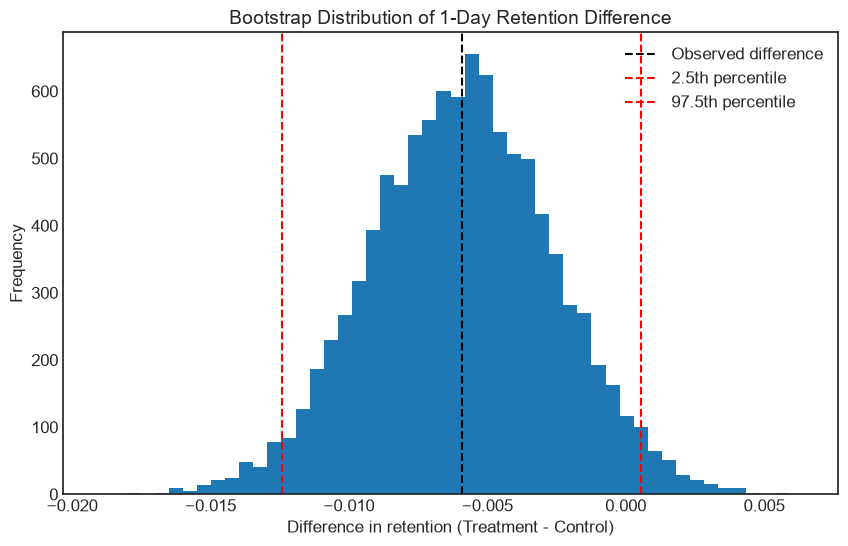

In [36]:
plt.figure(figsize=(10, 6))
plt.hist(bootstrap_diffs, bins=50)

plt.axvline(observed_diff, linestyle='--', color='black', label='Observed difference')
plt.axvline(ci_low_boot, linestyle='--', color='red', label='2.5th percentile')
plt.axvline(ci_high_boot, linestyle='--', color='red', label='97.5th percentile')

plt.xlabel('Difference in retention (Treatment - Control)')
plt.ylabel('Frequency')
plt.title('Bootstrap Distribution of 1-Day Retention Difference')
plt.legend()
plt.show()


<a id="segmentation"></a>
## 14. Deeper Analysis — Segmentation

[⬆ back to top](#toc)

**Caveat (stated up front, not just in the limitations section):** this
segmentation is exploratory / post-hoc -- we're cutting the data *after*
seeing it, on a variable (engagement level) that is itself partly a
consequence of the treatment. Treat any pattern found here as a hypothesis
to test in a dedicated follow-up experiment, not as a confirmed result.

In [37]:
median_rounds = df['sum_gamerounds'].median()

df['engagement_segment'] = np.where(
    df['sum_gamerounds'] <= median_rounds,
    'Low Engagement',
    'High Engagement'
)

print(df['engagement_segment'].value_counts())


engagement_segment
Low Engagement     45114
High Engagement    45074
Name: count, dtype: int64


In [38]:
# Re-run the 1-day retention test separately within each engagement segment,
# reusing the same helper function as the primary analysis.
for segment in ['Low Engagement', 'High Engagement']:
    segment_df = df[df['engagement_segment'] == segment]
    result_seg = run_two_proportion_test(segment_df, metric='retention_1')
    print(f"\n{segment}")
    print("-" * 30)
    print_test_result(result_seg)



Low Engagement
------------------------------
Metric:              retention_1
Control (gate_30):   16.14%  (n=22,169)
Treatment (gate_40): 16.15%  (n=22,945)
Difference:          0.02%
95% CI (Newcomb):    (-0.66%, 0.70%)
Z-statistic:         0.0477
P-value:             0.9620
Cohen's h:           0.0004
Verdict @ alpha=0.05: Fail to reject H0

High Engagement
------------------------------
Metric:              retention_1
Control (gate_30):   73.04%  (n=22,530)
Treatment (gate_40): 72.80%  (n=22,544)
Difference:          -0.24%
95% CI (Newcomb):    (-1.06%, 0.58%)
Z-statistic:         -0.5746
P-value:             0.5655
Cohen's h:           -0.0054
Verdict @ alpha=0.05: Fail to reject H0


<a id="bayesian"></a>
## 15. Bayesian A/B Test

[⬆ back to top](#toc)

As a complement to the frequentist tests above, we can model retention with
a Beta-Binomial conjugate model. Instead of a single p-value, this gives a
direct probability statement: *"What's the probability gate_30 beats gate_40?"*

In [39]:
gate_30 = df[df['version'] == 'gate_30']['retention_1']
gate_40 = df[df['version'] == 'gate_40']['retention_1']

success_30 = gate_30.sum()
success_40 = gate_40.sum()
failure_30 = len(gate_30) - success_30
failure_40 = len(gate_40) - success_40

alpha_prior = 1
beta_prior = 1

alpha_30 = alpha_prior + success_30
beta_30 = beta_prior + failure_30

alpha_40 = alpha_prior + success_40
beta_40 = beta_prior + failure_40

print("gate_30 posterior: Beta(", alpha_30, ",", beta_30, ")")
print("gate_40 posterior: Beta(", alpha_40, ",", beta_40, ")")


gate_30 posterior: Beta( 20035 , 24666 )
gate_40 posterior: Beta( 20120 , 25371 )


In [40]:
np.random.seed(RANDOM_SEED)
n_samples = 100000

posterior_30 = np.random.beta(alpha_30, beta_30, n_samples)
posterior_40 = np.random.beta(alpha_40, beta_40, n_samples)


In [41]:
prob_30_better = np.mean(posterior_30 > posterior_40)
prob_40_better = np.mean(posterior_40 > posterior_30)

print(f"P(gate_30 > gate_40): {prob_30_better:.2%}")
print(f"P(gate_40 > gate_30): {prob_40_better:.2%}")


P(gate_30 > gate_40): 96.29%
P(gate_40 > gate_30): 3.71%


<a id="interpretation"></a>
## 16. Interpretation & Business Framing

[⬆ back to top](#toc)

In [42]:
retention_summary = df.groupby('version')[['retention_1', 'retention_7']].mean()
print(retention_summary)
print()
print((retention_summary * 100).round(2))


         retention_1  retention_7
version                          
gate_30     0.448198     0.190183
gate_40     0.442283     0.182000

         retention_1  retention_7
version                          
gate_30        44.82        19.02
gate_40        44.23        18.20


In [43]:
summary_rows = []
for metric, result in [('retention_1', result_r1), ('retention_7', result_r7)]:
    summary_rows.append({
        'Metric': metric,
        'Gate_30': result['control_rate'] * 100,
        'Gate_40': result['treatment_rate'] * 100,
        'Difference_pp': result['diff'] * 100,
        'Z-statistic': result['z_stat'],
        'P-value (raw)': result['p_value'],
    })

results_df = pd.DataFrame(summary_rows)
results_df


,Metric,Gate_30,Gate_40,Difference_pp,Z-statistic,P-value (raw)
0,retention_1,44.819795,44.228275,-0.591520,-1.787104,0.073921
1,retention_7,19.018323,18.200004,-0.818318,-3.157410,0.001592


**Do the two metrics agree?** Both `retention_1` and `retention_7` point the
same direction (gate_30 retains slightly better than gate_40), but only the
7-day difference survives both the uncorrected significance test *and* the
multiple-comparisons correction in [Section 12](#multi-comp). This matters
because it suggests the effect of moving the gate compounds over time -- a
small day-1 dip that isn't reliably distinguishable from noise on its own
turns into a clearer, statistically robust gap by day 7.

In [44]:
control_prac = df[df['version'] == 'gate_30']['retention_1']
treatment_prac = df[df['version'] == 'gate_40']['retention_1']

absolute_effect = result_r1['diff']
relative_effect = absolute_effect / result_r1['control_rate']

print(f"Control retention:   {result_r1['control_rate']:.2%}")
print(f"Treatment retention: {result_r1['treatment_rate']:.2%}")
print(f"Absolute effect:     {absolute_effect:.2%}")
print(f"Relative effect:     {relative_effect:.2%}")


Control retention:   44.82%
Treatment retention: 44.23%
Absolute effect:     -0.59%
Relative effect:     -1.32%


In [45]:
# Define a business threshold for what counts as a "meaningful" change.
# NOTE: 1 percentage point is used here as an illustrative placeholder -- in a
# real setting this threshold should be derived from a revenue/LTV model
# (e.g. "a 1pp retention drop costs $X in projected lifetime value"), not
# picked arbitrarily. See Limitations.
business_threshold = 0.01

if result_r7['p_value'] < ALPHA and abs(result_r7['diff']) >= business_threshold:
    print("7-day retention: statistically significant AND above the practical threshold.")
elif result_r7['p_value'] < ALPHA:
    print("7-day retention: statistically significant, but effect is below the practical threshold.")
else:
    print("7-day retention: not statistically significant.")


7-day retention: statistically significant, but effect is below the practical threshold.


<a id="conclusion"></a>
## 17. Final Conclusion & Recommendation

[⬆ back to top](#toc)

**Summary of findings:**

- **Sample ratio:** no evidence of a sample ratio mismatch — the gate_30/gate_40 split is consistent with random 50/50 assignment (subject to the daily-SRM caveat in [Limitations](#limitations)).
- **1-day retention:** gate_30 (44.8%) slightly outperforms gate_40 (44.2%), a ~0.6 percentage-point gap that is **not** significant at the uncorrected α = 0.05 (p ≈ 0.074), and the test is likely **underpowered** to detect an effect this size (Section 11).
- **7-day retention:** gate_30 (19.0%) outperforms gate_40 (18.2%), a ~0.8 percentage-point gap that **is** significant — and is the **only** result that survives multiple-comparisons correction (Section 12).
- **Engagement (`sum_gamerounds`):** the Mann-Whitney U test does not survive correction either; the bootstrap and Bayesian analyses reinforce the same direction as the raw tests (gate_30 not worse), so there's no engagement upside from delaying the gate that would offset the retention cost.
- **Effect size:** Cohen's h for retention is small in absolute magnitude, but consistent in direction and larger/more reliable at day 7 than day 1.

**Recommendation:** Keep the first gate at level 30. After correcting for
multiple comparisons, the one result we can stand behind with confidence is a
statistically significant *decrease* in 7-day retention under gate_40, with
no offsetting gain in short-term retention or engagement. The 1-day result is
inconclusive rather than "no effect" (the test was underpowered for an effect
that size), so it should not be read as contradicting the 7-day finding.

**Suggested next step, given the limitations above:** before treating this as
final, (1) replace the illustrative 1pp business threshold with an actual
LTV-based one, and (2) if a daily install-date field can be added to the data
pipeline, re-run the SRM check on a day-by-day basis to rule out a
time-varying assignment issue before this result is used to make a permanent
product decision.
